### IMPORTING LIBRARIES

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

### GETTING STARTED WITH DATASET

In [2]:
df=pd.read_csv("../Datasets/Student_Addiction.csv")

In [3]:
df.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [31]:
df.describe()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,691369.000000,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000,691369.000000
mean,345684.000000,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866,0.709424
std,199581.183467,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006,0.454028
min,0.000000,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000,0.000000
25%,172842.000000,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000,0.000000
50%,345684.000000,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000,1.000000
75%,518526.000000,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000,1.000000
max,691368.000000,35.000000,15.000000,8.000000,4.000000,6.000000,9.000000,250.000000,180.000000,17.560000,1.000000


In [30]:
df.isnull().mean()*100

id                          0.000000
age                         4.184307
daily_screen_time_hours    13.864376
social_media_hours         19.381112
gaming_hours               18.343461
work_study_hours            7.451592
sleep_hours                 6.433612
notifications_per_day       9.775388
app_opens_per_day          11.673940
weekend_screen_time        16.208855
gender                      4.199494
stress_level                7.976638
academic_work_impact        6.396584
addicted_label              0.000000
dtype: float64

In [6]:
df.duplicated().sum()

np.int64(0)

## EXPLORATORY DATA ANALYSIS

In [ ]:
df.drop(columns=['id'],inplace=True)

In [8]:
num_cols=df.columns[df.nunique()>5]
cat_cols=df.columns[df.nunique()<5]

#### CATEGORICAL COLUMNS-ANALYSIS

##### DATA DISTRIBUTION

In [9]:
for cols in cat_cols:
    print('-'*50)
    print(df[cols].value_counts(normalize=True,dropna=False)*100)

--------------------------------------------------
gender
Male      32.350597
Female    32.051625
Other     31.398284
NaN        4.199494
Name: proportion, dtype: float64
--------------------------------------------------
stress_level
High      31.947195
Low       30.053850
Medium    30.022318
NaN        7.976638
Name: proportion, dtype: float64
--------------------------------------------------
academic_work_impact
Yes    47.813252
No     45.790164
NaN     6.396584
Name: proportion, dtype: float64
--------------------------------------------------
addicted_label
1    70.942435
0    29.057565
Name: proportion, dtype: float64


['8.95%', '9.49%', '9.39%']
['23.40%', '22.56%', '22.01%']
['8.84%', '8.68%', '9.22%']
['21.19%', '21.37%', '22.73%']
['13.23%', '13.97%']
['32.56%', '33.85%']
['29.06%']
['70.94%']


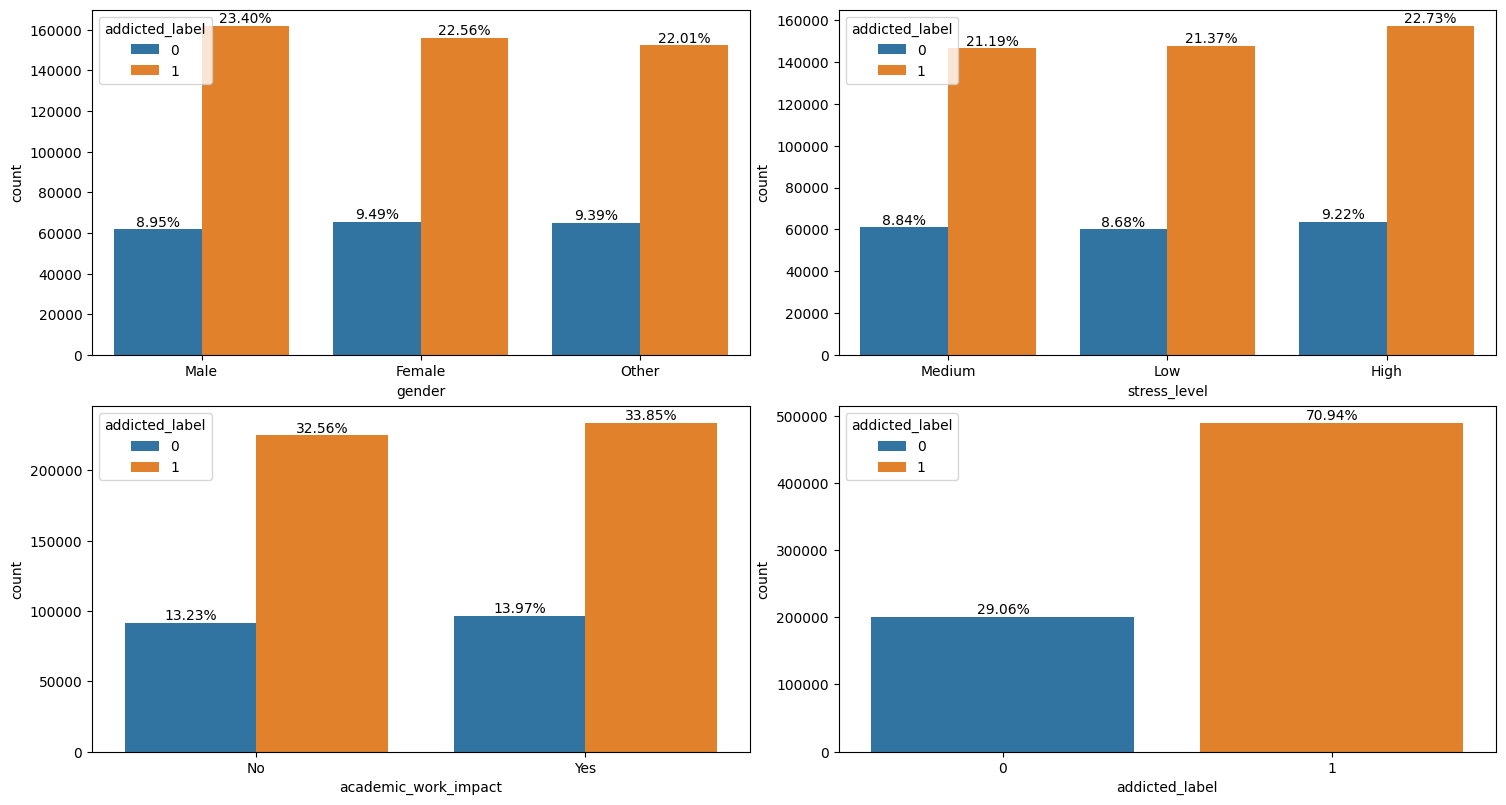

In [10]:
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(15,8))
ax=ax.flatten()
for i,cols in enumerate(cat_cols):
    axis=sns.countplot(x=cols,ax=ax[i],data=df,hue='addicted_label')
    total = len(df)
    for container in axis.containers:
        labels = [
            f'{value / total * 100:.2f}%'
            for value in container.datavalues
        ]
        axis.bar_label(container, labels=labels,)
        print(labels)
plt.tight_layout(pad=0.5)

##### missing values in categorical columns

In [12]:
for cols in cat_cols[0:3]:
    print('-'*50)
    print(pd.crosstab(index=df[cols],columns=df['addicted_label'],normalize='index',dropna=False)*100)

--------------------------------------------------
addicted_label          0          1
gender                              
Female          29.616192  70.383808
Male            27.680160  72.319840
Other           29.898009  70.101991
NaN             29.121031  70.878969
--------------------------------------------------
addicted_label          0          1
stress_level                        
High            28.856854  71.143146
Low             28.883980  71.116020
Medium          29.433671  70.566329
NaN             29.099877  70.900123
--------------------------------------------------
addicted_label                0          1
academic_work_impact                      
No                    28.897053  71.102947
Yes                   29.211716  70.788284
NaN                   29.054360  70.945640


- 70% of values are addicted and 30% of values are not addicted and the ratio is maintained throughout the data
- each category is equally weighted

##### PAIR-WISE ANALYSIS

In [17]:
pairs=[
    ('gender','stress_level'),
    ('gender','academic_work_impact'),
    ('stress_level','academic_work_impact')
]
for col1,col2 in pairs:
    print('-'*50)
    print(f'\n{col1} vs {col2}')
    print(pd.crosstab(df[col1],df[col2],normalize='index')*100)

--------------------------------------------------

gender vs stress_level
stress_level       High        Low     Medium
gender                                       
Female        34.156532  33.249903  32.593565
Male          33.938017  33.093110  32.968873
Other         36.127077  31.651085  32.221839
--------------------------------------------------

gender vs academic_work_impact
academic_work_impact         No        Yes
gender                                    
Female                49.027629  50.972371
Male                  49.197660  50.802340
Other                 48.552781  51.447219
--------------------------------------------------

stress_level vs academic_work_impact
academic_work_impact         No        Yes
stress_level                              
High                  47.520789  52.479211
Low                   49.619672  50.380328
Medium                49.661447  50.338553


- out of the misssing values  the distribution is 30% -0 and 70%-1 which aligns with the original data distribution so  better to use random imputation or missing indicator

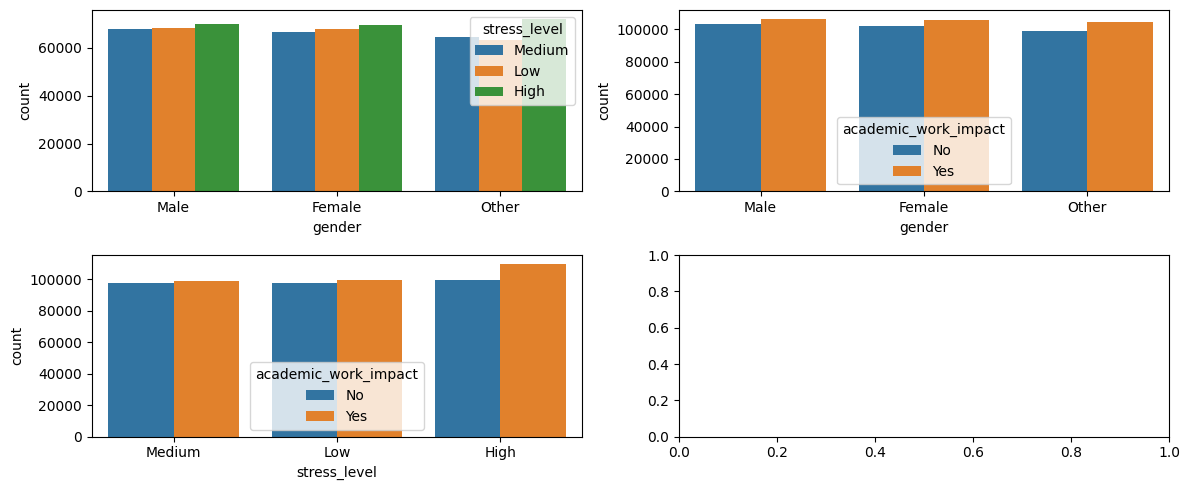

In [24]:
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(12,5))
ax=ax.ravel()
i=0
for col1,col2 in pairs:
    sns.countplot(x=col1,hue=col2,data=df,ax=ax[i])
    i=i+1
plt.tight_layout()

#### NUMERICAL COLUMN-ANALYSIS

##### INDIVIDUAL COLUMN ANALYSIS

In [17]:
df[num_cols].describe()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time
count,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000
mean,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866
std,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006
min,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000
25%,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000
50%,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000
75%,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000
max,35.000000,15.000000,8.000000,4.000000,6.000000,9.000000,250.000000,180.000000,17.560000


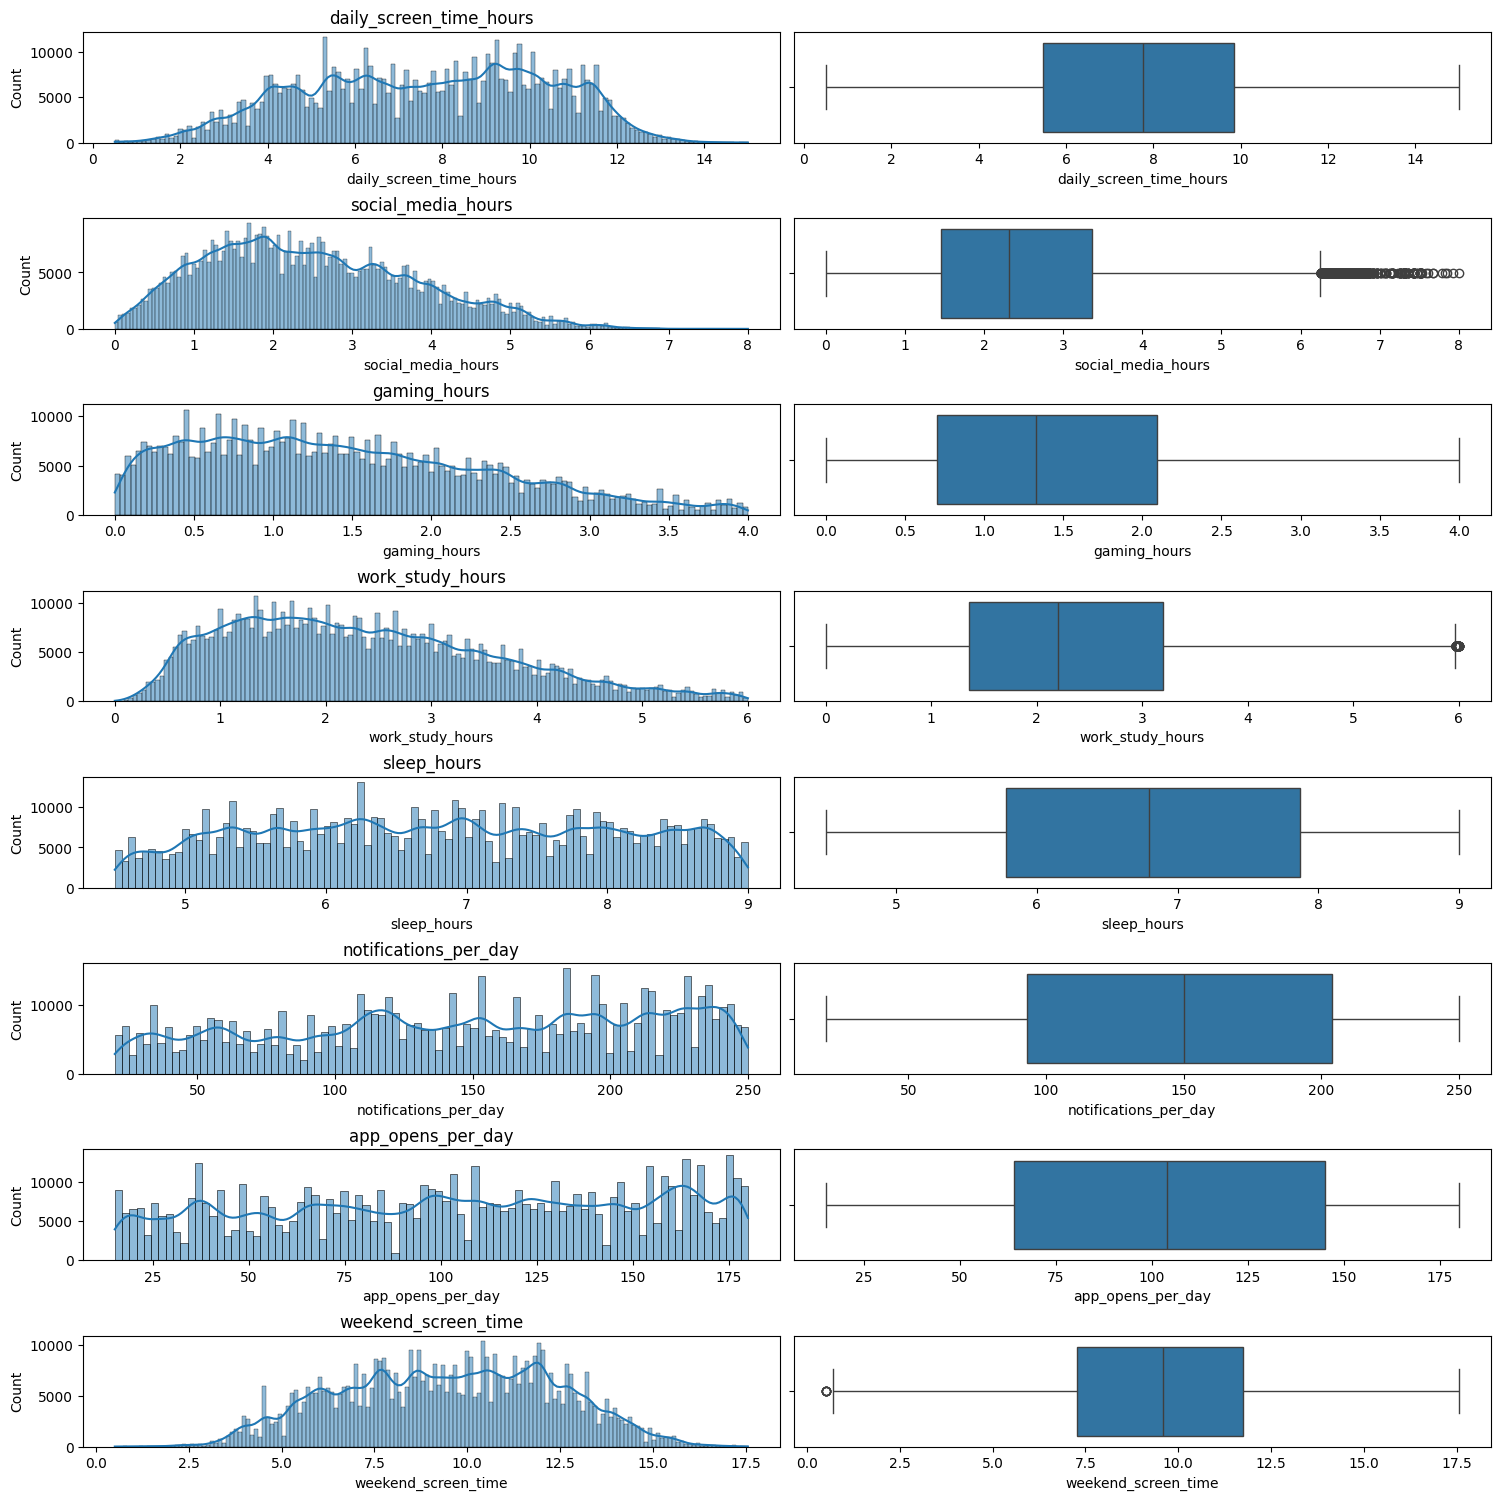

In [16]:
fig,ax=plt.subplots(nrows=len(num_cols)-1,ncols=2,figsize=(15,15))
for i,cols in enumerate(num_cols[1:]):
    sns.histplot(x=cols,data=df,ax=ax[i][0],kde=True)
    ax[i][0].set_title(cols)
    sns.boxplot(x=cols,data=df,ax=ax[i][1])
plt.tight_layout(pad=0.7)

In [25]:
#skewness of the data
df[num_cols].skew()

id                         9.539006e-17
age                       -3.680113e-02
daily_screen_time_hours   -1.319721e-01
social_media_hours         4.680814e-01
gaming_hours               5.447396e-01
work_study_hours           5.634571e-01
sleep_hours               -6.586670e-03
notifications_per_day     -2.065351e-01
app_opens_per_day         -1.264632e-01
weekend_screen_time       -6.340829e-02
dtype: float64

In [19]:
for cols in num_cols:
    print("-"*50)
    print(cols)
    print(pd.crosstab(df[cols]>df[cols].quantile(0.5),df['addicted_label'],normalize='index')*100)

--------------------------------------------------
age
addicted_label          0          1
age                                 
False           29.223155  70.776845
True            28.841253  71.158747
--------------------------------------------------
daily_screen_time_hours
addicted_label                   0          1
daily_screen_time_hours                      
False                    48.919755  51.080245
True                      2.757860  97.242140
--------------------------------------------------
social_media_hours
addicted_label              0          1
social_media_hours                      
False               44.230872  55.769128
True                 6.556364  93.443636
--------------------------------------------------
gaming_hours
addicted_label          0          1
gaming_hours                        
False           34.264428  65.735572
True            21.467826  78.532174
--------------------------------------------------
work_study_hours
addicted_label          

- from above result we can clearly find that there is more than 90% probability that if the value is greater than mean value then it was addicted for the columns: **daily_screen_time_hours**,**weekend_screen_time**,**social_media_hours**

In [48]:
#percentage of outliers
for cols in num_cols:
    #percentage of outliers
    q1=df[cols].quantile(0.25)
    q3=df[cols].quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    outliers=(df[cols]<lower)|(df[cols]>upper)
    print(cols ,"=",outliers.mean()*100,"%")

id = 0.0 %
age = 0.0 %
daily_screen_time_hours = 0.0 %
social_media_hours = 0.17487043821750758 %
gaming_hours = 0.0 %
work_study_hours = 0.04339216829218551 %
sleep_hours = 0.0 %
notifications_per_day = 0.0 %
app_opens_per_day = 0.0 %
weekend_screen_time = 0.0008678433658437101 %


<Axes: >

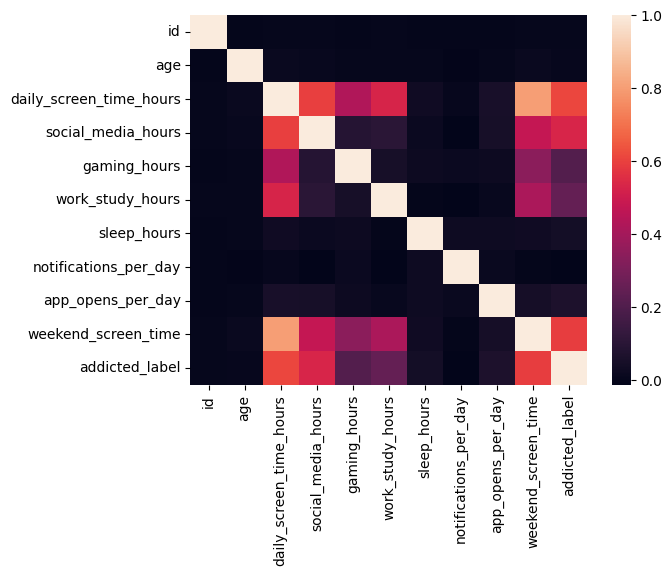

In [54]:
sns.heatmap(df.corr(numeric_only=True))

##### BIVARIATE ANALYSIS

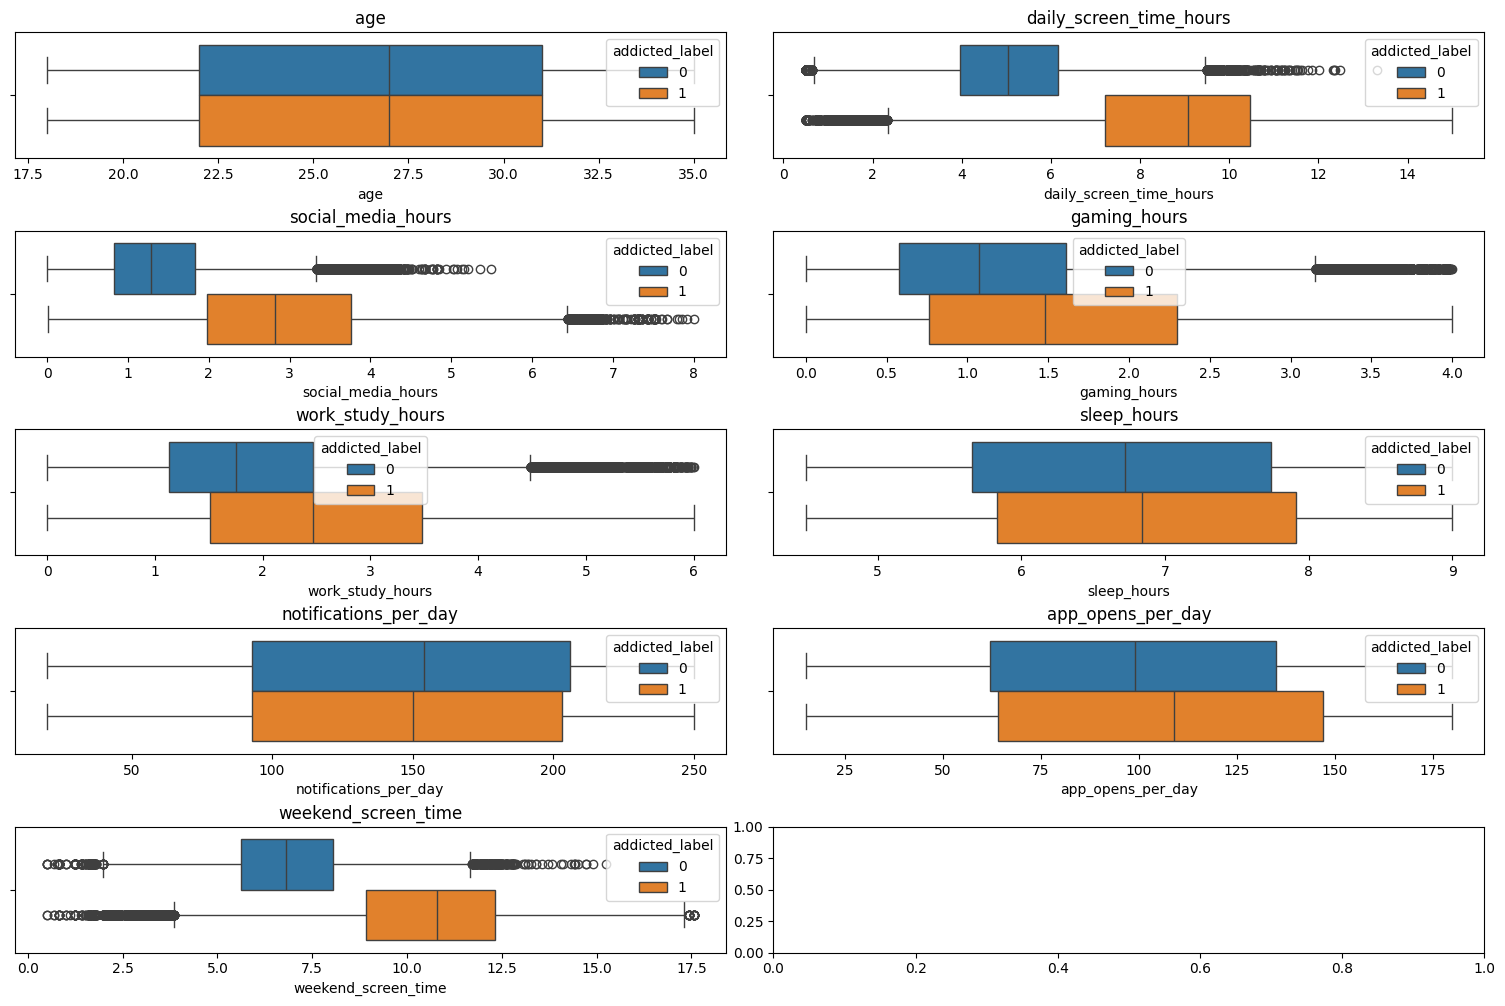

In [23]:
fig,ax=plt.subplots(nrows=len(num_cols)//2+1,ncols=2,figsize=(15,10))
for axis,cols in zip(ax.ravel(),num_cols):
    sns.boxplot(x=cols,hue='addicted_label',data=df,ax=axis)
    axis.set_title(cols)
plt.tight_layout(pad=0.5)

#### TARGET DISTRIBUTION ANALYSIS

In [55]:
df['addicted_label'].value_counts()

addicted_label
1    490474
0    200895
Name: count, dtype: int64

In [56]:
df['addicted_label'].value_counts(normalize=True)*100

addicted_label
1    70.942435
0    29.057565
Name: proportion, dtype: float64

##### how the targets are distributed in each category

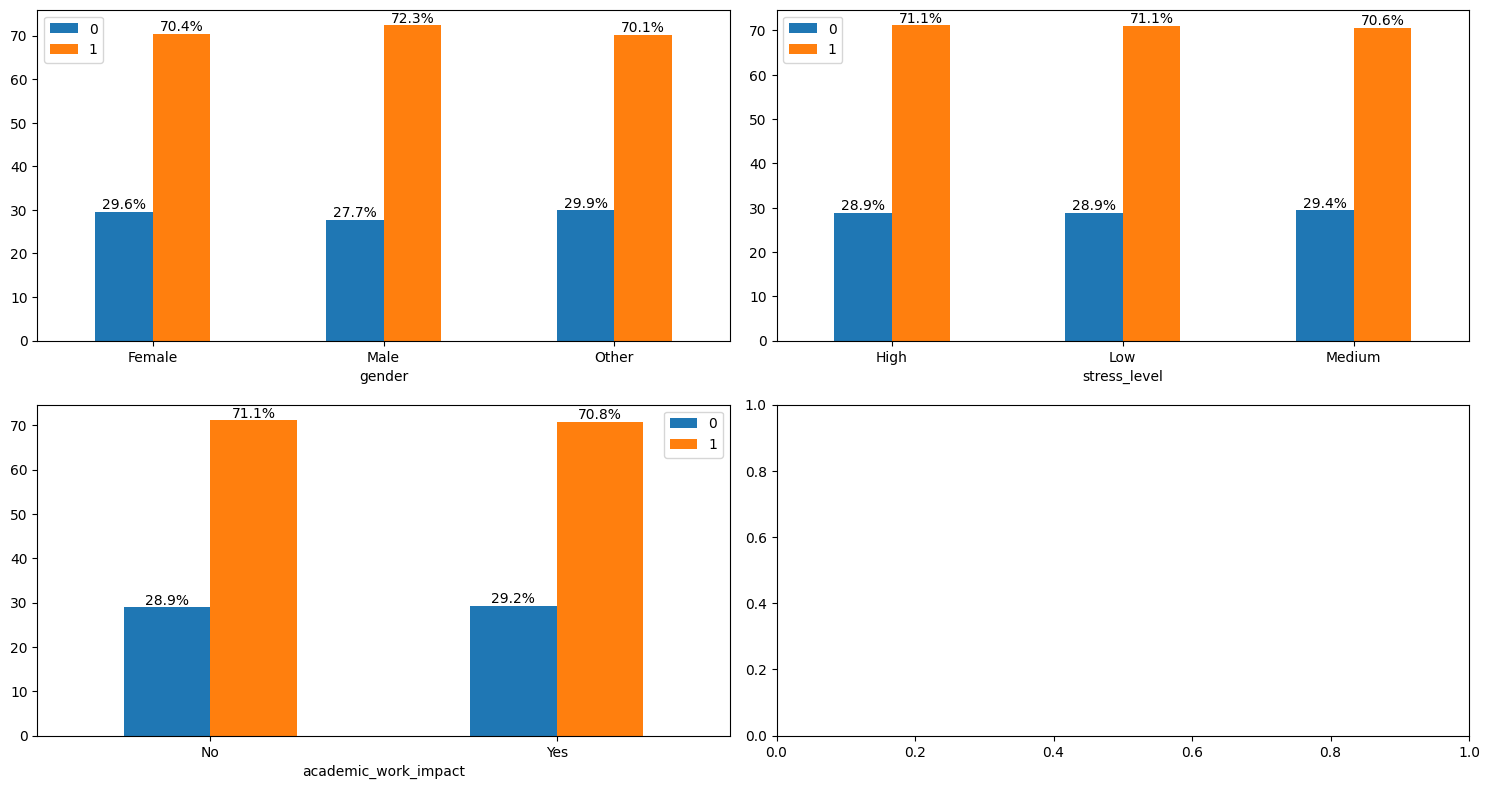

In [57]:
#in categorical columns
fig,ax=plt.subplots(ncols=2,nrows=2,figsize=(15,8))
ax=ax.flatten()
for i,cols in enumerate(cat_cols[0:3]):
    bars=pd.crosstab(df[cols],df['addicted_label'],normalize='index')*100
    axis=bars.plot(kind='bar',ax=ax[i])
    for container in axis.containers:
        axis.bar_label(container,fmt='%.1f%%')
    ax[i].tick_params(axis='x',rotation=0)
    axis.legend()
plt.tight_layout()

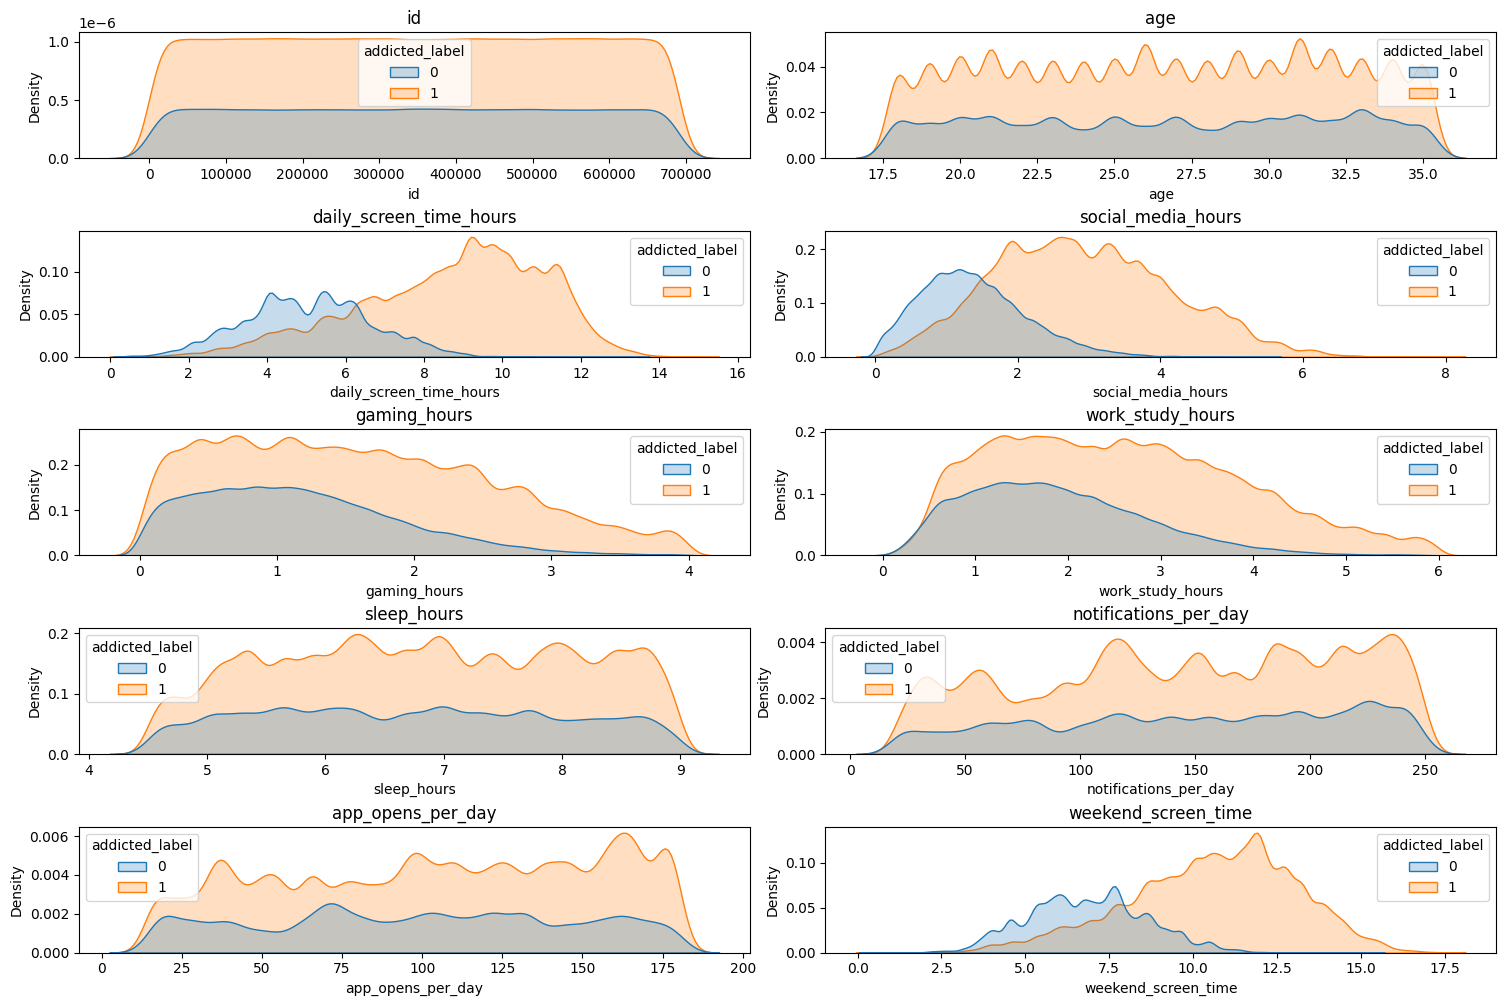

In [59]:
#in numerical columns
fig,ax=plt.subplots(nrows=len(num_cols)//2,ncols=2,figsize=(15,10))
for axis,cols in zip(ax.ravel(),num_cols):
    sns.kdeplot(x=cols,hue='addicted_label',data=df,ax=axis,fill=True)
    axis.set_title(cols)
plt.tight_layout(pad=0.5)

### SUMMARY

- The distribution of addicted people is addicted~ 70% and not-addicted~ 30% .
- Every column has missing values that ranges from **Age(4.184307)**  to **social_media_hours(19.381112)**.
- for all categorical columns(gender,stress_level,academic_work_impact) the distribution is almost equal throughtout all categories.
- Among students whose **daily_screen_time_hours**,**weekend_screen_time**,**social_media_hours**  is above the median, 95% of observations in this dataset are classified as addicted.